# Entrenamiento: demanda de bicicletas por día de la semana
Replica la estructura de `.PROFE_actividad-2/notebooks/train.ipynb`, adaptada al EDA de Seúl y a regresión: configuración, datos, partición, pipelines, entrenamiento, evaluación, MLflow y resumen. Sin Prefect ni importaciones de módulos del proyecto.

**Objetivo:** antes de comenzar un día, generar sus **24 predicciones horarias** y sumarlas para estimar las rentas del día completo. Se comparan **regresión lineal, Random Forest y Gradient Boosting**, con 65 % de entrenamiento y 35 % de prueba en orden cronológico.

El día de la semana es una entrada central, codificada como categoría para evitar inventar distancias entre lunes y domingo. También se incluyen fecha estacional y horario. No se promete que sea la variable más importante: eso depende de los datos y se comprueba al final. Multiplicar su código por un número no asegura mayor importancia en estos modelos.

**Decisiones del EDA:** conservar los ceros del archivo, identificados como ausencia de registros; no usarlos como etiquetas reales ni en métricas. La imputación retrospectiva de humedad con el mes posterior queda fuera del entrenamiento: además de usar futuro, el clima observado del día a predecir no está disponible de antemano. Esta versión usa únicamente calendario conocido y no necesita imputación meteorológica.

## 0. Librerías

In [1]:
import os
import json
import hashlib
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})


## 1. Configuración
La configuración se deja visible en el notebook, sin depender del YAML de churn. Las salidas se guardan en `notebook/artifacts/train_seoul_bike/`. MLflow se incluye como paso opcional: actívalo cuando tengas la biblioteca y el servidor configurados.

In [2]:
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/SeoulBikeData.csv").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("No se encuentra data/SeoulBikeData.csv")
cfg = {
    "train_size": .65,
    "test_size": .35,
    "semilla": 42,
    "objetivo": "alquileres",
    "horizonte_horas": 24,
    "registrar_mlflow": False,
    "experimento_mlflow": "seoul-bike-calendario",
    "candidatos": {
        "regresion_lineal": {},
        "random_forest": {"n_estimators": 200, "min_samples_leaf": 4,
                          "max_features": 1.0, "n_jobs": -1, "random_state": 42},
        "gradient_boosting": {"n_estimators": 200, "learning_rate": .05,
                              "max_depth": 3, "loss": "squared_error", "random_state": 42},
    },
}
SALIDAS = RAIZ / "notebook/artifacts/train_seoul_bike"
SALIDAS.mkdir(parents=True, exist_ok=True)
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
display(cfg)

{'train_size': 0.65,
 'test_size': 0.35,
 'semilla': 42,
 'objetivo': 'alquileres',
 'horizonte_horas': 24,
 'registrar_mlflow': False,
 'experimento_mlflow': 'seoul-bike-calendario',
 'candidatos': {'regresion_lineal': {},
  'random_forest': {'n_estimators': 200,
   'min_samples_leaf': 4,
   'max_features': 1.0,
   'n_jobs': -1,
   'random_state': 42},
  'gradient_boosting': {'n_estimators': 200,
   'learning_rate': 0.05,
   'max_depth': 3,
   'loss': 'squared_error',
   'random_state': 42}}}

## 2. Cargar datos y construir entradas de calendario
Se reconstruye la preparación del EDA desde el CSV: no es necesario ejecutar otro notebook ni compartir sus variables. Se conserva el archivo original y se construye un timestamp explícito.

Las variables predictoras son:
- **Día de semana:** siete categorías, sin orden numérico artificial.
- **Hora:** categoría; el mismo día puede tener demanda distinta en cada hora.
- **Fecha:** tendencia (días desde el inicio) y ciclo anual seno/coseno.
- **Interacciones de fin de semana y ciclo horario:** permiten a la regresión lineal cambiar el perfil horario en fines de semana; los árboles también aprenden interacciones.

Se conserva el objetivo original y se crea una máscara de registros observados. Los ceros no se imputan ni se eliminan del calendario.

In [3]:
ruta_csv = RAIZ / "data/SeoulBikeData.csv"
hash_csv = hashlib.sha256(ruta_csv.read_bytes()).hexdigest()
original = pd.read_csv(ruta_csv, encoding="utf-8")
requeridas = {"Date", "Hour", "Rented Bike Count"}
assert requeridas.issubset(original.columns), "Faltan columnas requeridas"
df = original[["Date", "Hour", "Rented Bike Count"]].rename(
    columns={"Date": "fecha", "Hour": "hora", "Rented Bike Count": "alquileres"}).copy()
df["fecha"] = pd.to_datetime(df.fecha, format="%d/%m/%Y", errors="raise")
assert df.hora.between(0, 23).all() and df.hora.mod(1).eq(0).all()
df["timestamp"] = df.fecha + pd.to_timedelta(df.hora, unit="h")
df = df.sort_values("timestamp").reset_index(drop=True)
assert df.timestamp.is_unique
assert df.alquileres.ge(0).all() and df.alquileres.mod(1).eq(0).all()
assert df[["fecha", "hora", "alquileres"]].notna().all().all()
esperadas = pd.date_range(df.timestamp.min(), df.timestamp.max(), freq="h")
assert pd.DatetimeIndex(df.timestamp).equals(esperadas), "Revisar horas faltantes"
df["registro_ausente"] = df.alquileres.eq(0)
ORIGEN_FECHA = df.fecha.min()

def crear_features(timestamps):
    # Solo calendario: no recibe conteos ni clima del futuro.
    t = pd.Series(pd.to_datetime(timestamps)).reset_index(drop=True)
    x = pd.DataFrame(index=t.index)
    x["dia_semana"] = t.dt.dayofweek.astype(int)
    x["hora"] = t.dt.hour.astype(int)
    x["dias_desde_inicio"] = (t.dt.normalize() - ORIGEN_FECHA).dt.days
    angulo_anual = 2 * np.pi * (t.dt.dayofyear - 1) / 365.25
    x["fecha_sin"] = np.sin(angulo_anual)
    x["fecha_cos"] = np.cos(angulo_anual)
    fin_semana = t.dt.dayofweek.ge(5).astype(int)
    x["fin_semana_hora_sin"] = fin_semana * np.sin(2*np.pi*t.dt.hour/24)
    x["fin_semana_hora_cos"] = fin_semana * np.cos(2*np.pi*t.dt.hour/24)
    return x

CATEGORICAS = ["dia_semana", "hora"]
NUMERICAS = ["dias_desde_inicio", "fecha_sin", "fecha_cos",
             "fin_semana_hora_sin", "fin_semana_hora_cos"]
FEATURES = CATEGORICAS + NUMERICAS
OBJETIVO = cfg["objetivo"]
print("Registros:", len(df), "| Objetivos ausentes:", df.registro_ausente.sum())
display(df.head())
display(crear_features(df.timestamp).head())

Registros: 8760 | Objetivos ausentes: 295


,fecha,hora,alquileres,timestamp,registro_ausente
0,2017-12-01,0,254,2017-12-01 00:00:00,False
1,2017-12-01,1,204,2017-12-01 01:00:00,False
2,2017-12-01,2,173,2017-12-01 02:00:00,False
3,2017-12-01,3,107,2017-12-01 03:00:00,False
4,2017-12-01,4,78,2017-12-01 04:00:00,False


,dia_semana,hora,dias_desde_inicio,fecha_sin,fecha_cos,fin_semana_hora_sin,fin_semana_hora_cos
0,4,0,0,-0.512,0.859,0.000,0.000
1,4,1,0,-0.512,0.859,0.000,0.000
2,4,2,0,-0.512,0.859,0.000,0.000
3,4,3,0,-0.512,0.859,0.000,0.000
4,4,4,0,-0.512,0.859,0.000,0.000


## 3. Partición: entrenamiento 65 % / prueba 35 %
Se ordenan los días y se asigna el primer 65 % a entrenamiento. Se redondea hacia abajo al día completo más próximo: esto evita cortar una jornada entre entrenamiento y prueba, aunque el porcentaje no sea exactamente 65,000 %.

La división se hace **antes** de excluir etiquetas ausentes. Las horas permanecen en el calendario y se predicen; solo se omiten del ajuste y del cálculo del error cuando no hay alquileres observados. No se hace estratificación ni mezcla aleatoria. Los hiperparámetros se fijan antes de mirar prueba.

In [4]:
dias = pd.Index(df.fecha.drop_duplicates())
n_dias_train = int(len(dias) * cfg["train_size"])
fecha_corte = dias[n_dias_train]
train_calendario = df.loc[df.fecha < fecha_corte].copy()
test_calendario = df.loc[df.fecha >= fecha_corte].copy()
train_df = train_calendario.loc[~train_calendario.registro_ausente].copy()
test_df = test_calendario.loc[~test_calendario.registro_ausente].copy()
assert train_calendario.timestamp.max() < test_calendario.timestamp.min()
assert set(train_df.fecha).isdisjoint(test_df.fecha)
assert len(train_calendario) + len(test_calendario) == len(df)

particion = pd.DataFrame([
    {"conjunto": nombre, "desde": calendario.timestamp.min(), "hasta": calendario.timestamp.max(),
     "dias": calendario.fecha.nunique(), "horas_calendario": len(calendario),
     "porcentaje_calendario": 100*len(calendario)/len(df),
     "etiquetas_observadas": len(observados), "horas_ausentes": calendario.registro_ausente.sum()}
    for nombre, calendario, observados in [
        ("train", train_calendario, train_df), ("test", test_calendario, test_df)]
])
display(particion)
X_train, y_train = crear_features(train_df.timestamp), train_df[OBJETIVO].reset_index(drop=True)
X_test, y_test = crear_features(test_df.timestamp), test_df[OBJETIVO].reset_index(drop=True)
print("Features:", FEATURES)
display(pd.crosstab(df.fecha.lt(fecha_corte).map({True:"train", False:"test"}), df.fecha.dt.dayofweek)
        .rename(columns=dict(enumerate(DIAS))))

,conjunto,desde,hasta,dias,horas_calendario,porcentaje_calendario,etiquetas_observadas,horas_ausentes
0,train,2017-12-01,2018-07-25 23:00:00,237,5688,64.932,5640,48
1,test,2018-07-26,2018-11-30 23:00:00,128,3072,35.068,2825,247


Features: ['dia_semana', 'hora', 'dias_desde_inicio', 'fecha_sin', 'fecha_cos', 'fin_semana_hora_sin', 'fin_semana_hora_cos']


fecha,Lunes,Martes,Miércoles,Jueves,Viernes,Sábado,Domingo
fecha,,,,,,,
test,432,432,432,456,456,432,432
train,816,816,816,792,816,816,816


## 4. Pipelines: preprocesado + tres regresores
El escalado y el one-hot se ajustan solo con entrenamiento. El día de semana entra como categoría en los tres modelos y no se elimina por una selección previa.

No se duplican ni multiplican sus columnas para simular importancia. El escalado de una variable no obliga a un árbol a usarla y la regresión puede compensarlo con su coeficiente. La importancia del grupo semanal se medirá por el aumento del error al alterar ese calendario.

Las predicciones negativas se limitan a cero al evaluar y pronosticar; se conservan también las salidas originales para auditar esta decisión.

In [5]:
preprocesado = ColumnTransformer([
    ("num", StandardScaler(), NUMERICAS),
    ("cat", OneHotEncoder(categories=[list(range(7)), list(range(24))],
                          drop="first", handle_unknown="ignore",
                          sparse_output=False), CATEGORICAS),
])
estimadores = {
    "regresion_lineal": LinearRegression(**cfg["candidatos"]["regresion_lineal"]),
    "random_forest": RandomForestRegressor(**cfg["candidatos"]["random_forest"]),
    "gradient_boosting": GradientBoostingRegressor(**cfg["candidatos"]["gradient_boosting"]),
}
pipelines = {
    nombre: Pipeline([("preprocesado", clone(preprocesado)), ("modelo", estimador)])
    for nombre, estimador in estimadores.items()
}
display(pipelines["regresion_lineal"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocesado', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers c

## 5. Entrenar
Los tres candidatos usan exactamente las mismas filas y variables. No se reentrenan con prueba ni se ajustan hiperparámetros usando sus resultados.

In [6]:
tiempos = {}
for nombre, pipeline in pipelines.items():
    inicio = time.perf_counter()
    pipeline.fit(X_train, y_train)
    tiempos[nombre] = time.perf_counter() - inicio
    print(f"{nombre}: entrenado en {tiempos[nombre]:.2f} s")

regresion_lineal: entrenado en 0.03 s


random_forest: entrenado en 0.71 s


gradient_boosting: entrenado en 0.97 s


## 6. Evaluación horaria y del día completo
**MAE:** error absoluto promedio, en rentas. **RMSE:** penaliza más los errores grandes. **R²:** comparación con una referencia constante del conjunto evaluado; puede ser negativo. No se usa MAPE por las ausencias y los conteos pequeños.

Referencias ajustadas solo con train: media global y media por combinación de día de semana y hora. Se predicen todas las horas de prueba, pero las métricas horarias usan solo etiquetas observadas. Los totales diarios se evalúan **únicamente en días con 24 registros observados**: un total parcial no es una verdad diaria completa.

La tabla de prueba permite comparar estos candidatos fijos, pero no sustituye validación temporal para elegir hiperparámetros ni demuestra rendimiento en otros años.

In [7]:
def metricas_regresion(real, pred):
    return {"mae": float(mean_absolute_error(real, pred)),
            "rmse": float(np.sqrt(mean_squared_error(real, pred))),
            "r2": float(r2_score(real, pred))}

evaluacion = test_calendario[["timestamp", "fecha", "hora", OBJETIVO, "registro_ausente"]].reset_index(drop=True)
evaluacion["dia_semana"] = evaluacion.fecha.dt.dayofweek
X_test_completo = crear_features(evaluacion.timestamp)
media_global = float(y_train.mean())
media_dia_hora = train_df.assign(dia_semana=train_df.fecha.dt.dayofweek).groupby(
    ["dia_semana", "hora"])[OBJETIVO].mean()
indice_dia_hora = pd.MultiIndex.from_frame(evaluacion[["dia_semana", "hora"]])
predicciones = {
    "referencia_global": np.full(len(evaluacion), media_global),
    "referencia_dia_hora": media_dia_hora.reindex(indice_dia_hora).fillna(media_global).to_numpy(),
}
filas_metricas = []
observado = ~evaluacion.registro_ausente
for nombre, pipeline in pipelines.items():
    bruto = pipeline.predict(X_test_completo)
    evaluacion[f"{nombre}_sin_recorte"] = bruto
    predicciones[nombre] = np.maximum(bruto, 0)
for nombre, pred in predicciones.items():
    assert len(pred) == len(evaluacion) and np.isfinite(pred).all()
    evaluacion[nombre] = pred
    m = metricas_regresion(evaluacion.loc[observado, OBJETIVO], pred[observado])
    m.update({"modelo": nombre, "segundos_fit": tiempos.get(nombre, 0)})
    filas_metricas.append(m)
metricas_horarias = pd.DataFrame(filas_metricas).set_index("modelo").sort_values("mae")
display(metricas_horarias)

diario = evaluacion.groupby("fecha").agg(
    total_archivo=(OBJETIVO, "sum"), horas_observadas=("registro_ausente", lambda s: (~s).sum()))
for nombre in predicciones:
    diario[nombre] = evaluacion.groupby("fecha")[nombre].sum()
diario["dia_completo_observado"] = diario.horas_observadas.eq(24)
completos = diario.loc[diario.dia_completo_observado]
assert len(completos) >= 2
metricas_diarias = pd.DataFrame({
    nombre: metricas_regresion(completos.total_archivo, completos[nombre])
    for nombre in predicciones
}).T.sort_values("mae")
display(metricas_diarias)
print("Días de prueba:", len(diario), "| Días completos evaluables:", len(completos),
      "| Días con ausencia:", (~diario.dia_completo_observado).sum())
assert evaluacion.loc[observado, OBJETIVO].gt(0).all()


,mae,rmse,r2,segundos_fit
modelo,,,,
random_forest,305.245,431.563,0.485,0.708
gradient_boosting,329.669,446.463,0.449,0.975
referencia_dia_hora,365.912,485.711,0.348,0.000
referencia_global,498.997,660.084,-0.204,0.000
regresion_lineal,648.022,812.679,-0.826,0.032


,mae,rmse,r2
random_forest,"6,377.667","7,505.477",-0.480
gradient_boosting,"6,536.552","7,564.057",-0.504
referencia_global,"7,715.845","8,977.182",-1.118
referencia_dia_hora,"7,720.874","9,002.029",-1.130
regresion_lineal,"14,290.491","16,661.419",-6.295


Días de prueba: 128 | Días completos evaluables: 117 | Días con ausencia: 11


### 6.1 Gráficos y errores por día de la semana
Se muestran los tres candidatos, no solo el de menor error. Las diferencias entre periodos pueden reflejar estación y clima no disponible en este modelo.

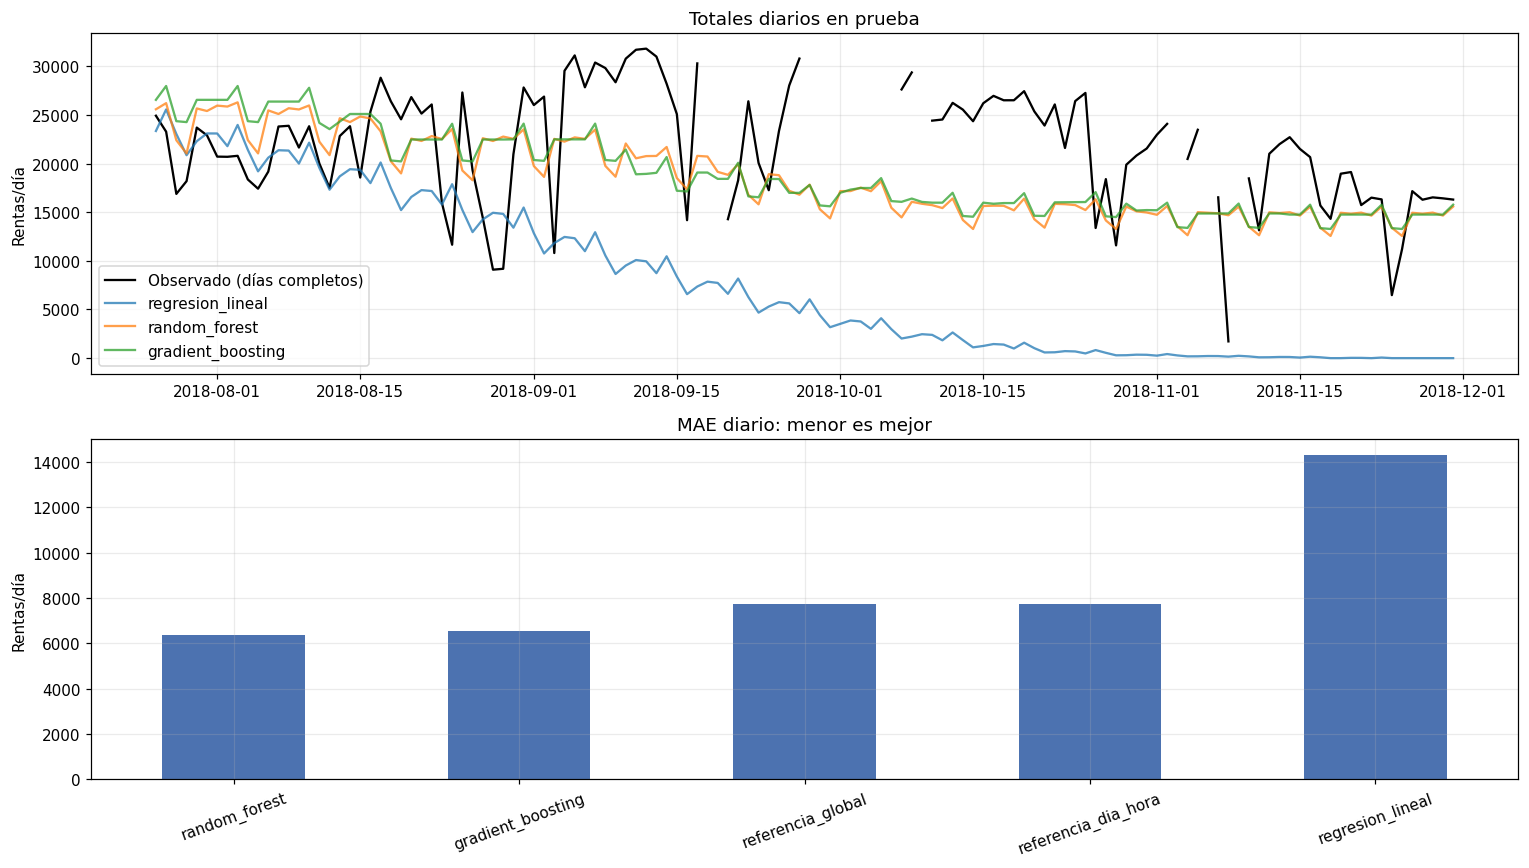

modelo,gradient_boosting,random_forest,regresion_lineal
grupo,,,
Lunes,361.757,320.080,714.402
Martes,324.802,282.977,664.889
Miércoles,353.626,334.754,715.412
Jueves,326.785,306.110,627.695
Viernes,325.553,303.107,593.816
Sábado,342.166,326.102,637.960
Domingo,270.632,259.087,582.074


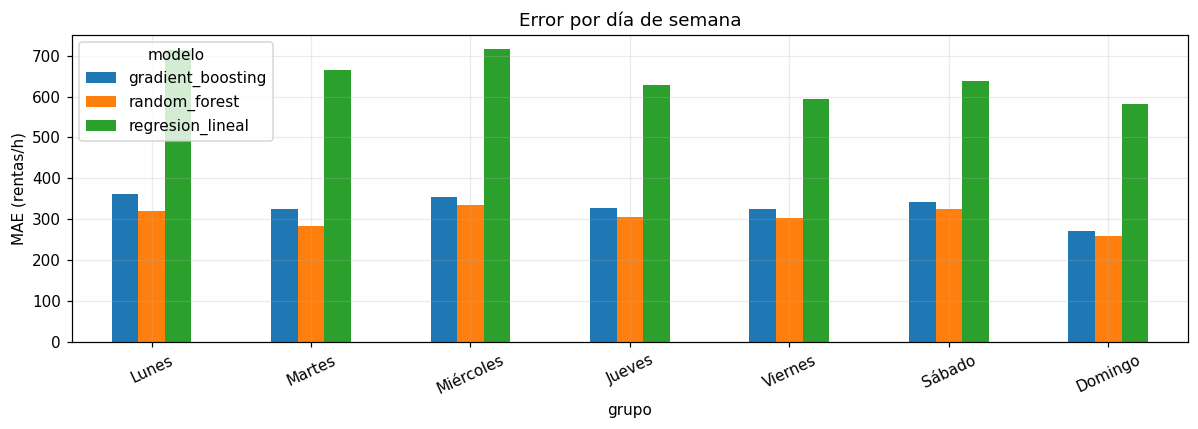

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
real_diario = diario.total_archivo.where(diario.dia_completo_observado)
axes[0].plot(diario.index, real_diario, color="black", lw=1.5, label="Observado (días completos)")
for nombre in pipelines:
    axes[0].plot(diario.index, diario[nombre], alpha=.75, label=nombre)
axes[0].set(title="Totales diarios en prueba", ylabel="Rentas/día")
axes[0].legend()
metricas_diarias["mae"].plot.bar(ax=axes[1], color="#4C72B0")
axes[1].set(title="MAE diario: menor es mejor", ylabel="Rentas/día")
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout(); plt.show()

errores_grupo = []
for nombre in pipelines:
    e = evaluacion.loc[observado].copy()
    e["error_abs"] = (e[OBJETIVO] - e[nombre]).abs()
    for variable in ["dia_semana", "hora"]:
        t = e.groupby(variable).error_abs.agg(["size", "mean"]).reset_index()
        t.columns = ["grupo", "horas_observadas", "mae"]
        t["variable"], t["modelo"] = variable, nombre
        errores_grupo.append(t)
errores_segmentos = pd.concat(errores_grupo, ignore_index=True)
tabla_semana = errores_segmentos.query("variable == 'dia_semana'").pivot(
    index="grupo", columns="modelo", values="mae").rename(index=dict(enumerate(DIAS)))
display(tabla_semana)
ax = tabla_semana.plot.bar(figsize=(11,4), ylabel="MAE (rentas/h)", title="Error por día de semana")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()


### 6.2 Importancia medida del día de la semana
Se altera el calendario semanal de días enteros de prueba, conservando la misma hora para las 24 filas de cada día y recalculando sus interacciones. Se compara con alterar las variables de fecha. El aumento de MAE indica cuánto dependía el modelo de ese grupo de entradas.

Es un diagnóstico sobre prueba, no una prueba causal ni un motivo para retocar el modelo con esos mismos resultados. Un aumento pequeño o negativo indica poca utilidad de ese grupo en este periodo. No se debe afirmar que el día domina si el resultado no lo respalda.

In [9]:
rng = np.random.default_rng(cfg["semilla"])
dias_test = pd.Index(evaluacion.fecha.drop_duplicates())
mapa_dia_fila = evaluacion.fecha.map(pd.Series(np.arange(len(dias_test)), index=dias_test)).to_numpy()
importancias = []
for nombre, pipeline in pipelines.items():
    mae_base = mean_absolute_error(evaluacion.loc[observado, OBJETIVO], predicciones[nombre][observado])
    for grupo in ["dia_semana", "fecha"]:
        aumentos = []
        for repeticion in range(5):
            orden = rng.permutation(len(dias_test))
            fechas_permutadas = pd.Series(dias_test[orden[mapa_dia_fila]]) + pd.to_timedelta(evaluacion.hora, unit="h")
            artificial = crear_features(fechas_permutadas)
            alterado = X_test_completo.copy()
            columnas = (["dia_semana", "fin_semana_hora_sin", "fin_semana_hora_cos"]
                        if grupo == "dia_semana" else ["dias_desde_inicio", "fecha_sin", "fecha_cos"])
            alterado[columnas] = artificial[columnas]
            pred = np.maximum(pipeline.predict(alterado), 0)
            aumentos.append(mean_absolute_error(evaluacion.loc[observado, OBJETIVO], pred[observado]) - mae_base)
        importancias.append({"modelo": nombre, "grupo": grupo,
                             "aumento_mae": np.mean(aumentos), "dispersion_repeticiones": np.std(aumentos)})
importancias_calendario = pd.DataFrame(importancias)
display(importancias_calendario)
print("La dispersión entre permutaciones no es un intervalo de confianza temporal.")


,modelo,grupo,aumento_mae,dispersion_repeticiones
0,regresion_lineal,dia_semana,0.763,1.482
1,regresion_lineal,fecha,14.299,5.586
2,random_forest,dia_semana,32.261,2.347
3,random_forest,fecha,33.437,7.863
4,gradient_boosting,dia_semana,15.419,3.527
5,gradient_boosting,fecha,12.234,8.806


La dispersión entre permutaciones no es un intervalo de confianza temporal.


## 7. Registro en MLflow y artefactos locales
Se guardan configuración, métricas, predicciones, información de partición y los tres pipelines. Un archivo de metadatos documenta el origen usado para construir variables y el recorte de predicciones negativas. El pipeline recibe FEATURES, no fechas crudas: para servirlo hay que aplicar la misma función `crear_features`.

Como en el notebook de referencia, MLflow puede registrar parámetros, métricas, firma, ejemplos y modelos. Está desactivado por defecto para poder ejecutar entrenamiento sin servidor. Para habilitarlo: instalar MLflow en el kernel, configurar `MLFLOW_TRACKING_URI` y cambiar `registrar_mlflow=True` en la configuración. No se promueven modelos al Registry automáticamente.

In [10]:
with open(SALIDAS / "config.json", "w", encoding="utf-8") as f:
    json.dump(cfg, f, ensure_ascii=False, indent=2)
metadatos = {
    "dataset_sha256": hash_csv, "origen_fecha": ORIGEN_FECHA.isoformat(),
    "features": FEATURES, "categoricas": CATEGORICAS, "numericas": NUMERICAS,
    "fecha_corte": fecha_corte.isoformat(), "horizonte_horas": 24,
    "objetivo_ausente": "conteo original igual a cero",
    "prediccion": "maximum(pipeline.predict(crear_features(timestamps)), 0)",
    "nota": "Calendario sin meteorología ni rezagos. Totales diarios evaluados solo con 24 etiquetas.",
}
with open(SALIDAS / "metadatos.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)
for nombre, pipeline in pipelines.items():
    joblib.dump(pipeline, SALIDAS / f"{nombre}.joblib")
for nombre, tabla in {
    "metricas_horarias": metricas_horarias, "metricas_diarias": metricas_diarias,
    "particion": particion, "predicciones_horarias": evaluacion,
    "predicciones_diarias": diario, "errores_segmentos": errores_segmentos,
    "importancias_calendario": importancias_calendario,
}.items():
    tabla.to_csv(SALIDAS / f"{nombre}.csv", index=True)
# Verificar que persistir el modelo conserva sus predicciones.
for nombre in pipelines:
    recuperado = joblib.load(SALIDAS / f"{nombre}.joblib")
    np.testing.assert_allclose(recuperado.predict(X_test.head(24)), pipelines[nombre].predict(X_test.head(24)))
assert hashlib.sha256(ruta_csv.read_bytes()).hexdigest() == hash_csv
print("Artefactos guardados en:", SALIDAS)


Artefactos guardados en: C:\Users\segep\OneDrive\Documents\Personal\Maestria en Ciencia de Datos\Semestre 3\MLOps\Proyecto\proyecto_mlp_usta\notebook\artifacts\train_seoul_bike


In [11]:
runs_mlflow = {}
if cfg["registrar_mlflow"]:
    import mlflow
    import mlflow.sklearn
    from mlflow.models import infer_signature
    mlflow.set_tracking_uri(os.environ.get("MLFLOW_TRACKING_URI", "http://localhost:5000"))
    mlflow.set_experiment(cfg["experimento_mlflow"])
    for nombre, pipeline in pipelines.items():
        with mlflow.start_run(run_name=nombre) as run:
            mlflow.log_params({"modelo": nombre, "train_size": cfg["train_size"],
                               "horizonte_horas": 24, "fecha_corte": str(fecha_corte),
                               "features": ",".join(FEATURES), **cfg["candidatos"][nombre]})
            mlflow.log_metrics({f"horario_{k}": float(metricas_horarias.loc[nombre, k])
                                for k in ["mae", "rmse", "r2"]})
            mlflow.log_metrics({f"diario_{k}": float(metricas_diarias.loc[nombre, k])
                                for k in ["mae", "rmse", "r2"]})
            mlflow.log_artifact(str(SALIDAS / "metadatos.json"))
            mlflow.log_artifact(str(SALIDAS / "predicciones_diarias.csv"))
            mlflow.sklearn.log_model(
                pipeline, name="model",
                signature=infer_signature(X_train.head(24), pipeline.predict(X_train.head(24))),
                input_example=X_train.head(3))
            mlflow.set_tag("postprocesamiento", "recortar predicciones negativas a cero antes de evaluar")
            runs_mlflow[nombre] = run.info.run_id
    display(runs_mlflow)
else:
    print("MLflow desactivado. Modelos y resultados disponibles como artefactos locales.")


MLflow desactivado. Modelos y resultados disponibles como artefactos locales.


## 8. Ejemplo: predecir el día completo
El ejemplo usa los tres modelos entrenados solo con el bloque inicial, sin reentrenar con prueba. El día elegido es posterior al final del CSV. No hay un valor real para evaluar este pronóstico; es una demostración de inferencia. Los valores esperados son continuos, sin redondear cada hora para calcular métricas o totales.

In [12]:
dia_futuro = df.fecha.max() + pd.Timedelta(days=1)
timestamps_futuros = pd.date_range(dia_futuro, periods=24, freq="h")
X_futuro = crear_features(timestamps_futuros)
pronostico = pd.DataFrame({"timestamp": timestamps_futuros,
                           "dia_semana": DIAS[dia_futuro.dayofweek]})
for nombre, pipeline in pipelines.items():
    pronostico[nombre] = np.maximum(pipeline.predict(X_futuro), 0)
display(pronostico)
totales_futuros = pronostico[list(pipelines)].sum().rename("rentas_dia_estimadas")
display(totales_futuros.to_frame())
assert len(pronostico) == 24 and pronostico.timestamp.dt.normalize().nunique() == 1
pronostico.to_csv(SALIDAS / "ejemplo_pronostico_24h.csv", index=False)


,timestamp,dia_semana,regresion_lineal,random_forest,gradient_boosting
0,2018-12-01 00:00:00,Sábado,0.000,537.691,595.864
1,2018-12-01 01:00:00,Sábado,0.000,477.031,408.685
2,2018-12-01 02:00:00,Sábado,0.000,350.796,319.465
3,2018-12-01 03:00:00,Sábado,0.000,254.693,197.676
4,2018-12-01 04:00:00,Sábado,0.000,163.126,61.905
5,2018-12-01 05:00:00,Sábado,0.000,138.287,29.116
6,2018-12-01 06:00:00,Sábado,0.000,170.001,153.299
7,2018-12-01 07:00:00,Sábado,0.000,266.575,356.107
8,2018-12-01 08:00:00,Sábado,0.000,449.224,485.061
9,2018-12-01 09:00:00,Sábado,0.000,496.766,430.440


,rentas_dia_estimadas
regresion_lineal,0.000
random_forest,"13,395.971"
gradient_boosting,"13,362.415"


## 9. Resumen y limitaciones

In [13]:
comparacion_candidatos = metricas_diarias.loc[list(pipelines)].sort_values("mae")
menor_error = comparacion_candidatos.index[0]
display(Markdown(
    f"**Menor MAE diario entre los tres candidatos en esta prueba:** {menor_error}.\n\n"
    f"- MAE diario: **{comparacion_candidatos.loc[menor_error, 'mae']:,.1f} rentas/día**.\n"
    f"- Días completos evaluados: {len(completos)} de {len(diario)}.\n"
    f"- Entrenamiento: {len(train_calendario)/len(df):.2%} del calendario; "
    f"prueba: {len(test_calendario)/len(df):.2%}.\n"
    f"- Etiquetas de entrenamiento: {len(train_df):,}; prueba: {len(test_df):,}.\n"
    f"- Resultados y pipelines: notebook/artifacts/train_seoul_bike/."
))
display(comparacion_candidatos)


**Menor MAE diario entre los tres candidatos en esta prueba:** random_forest.

- MAE diario: **6,377.7 rentas/día**.
- Días completos evaluados: 117 de 128.
- Entrenamiento: 64.93% del calendario; prueba: 35.07%.
- Etiquetas de entrenamiento: 5,640; prueba: 2,825.
- Resultados y pipelines: notebook/artifacts/train_seoul_bike/.

,mae,rmse,r2
random_forest,"6,377.667","7,505.477",-0.480
gradient_boosting,"6,536.552","7,564.057",-0.504
regresion_lineal,"14,290.491","16,661.419",-6.295


**Cómo interpretar el resultado**
- Un modelo de calendario aprende patrones por día, horario y época del año. No puede anticipar lluvia, cierres o acontecimientos que no estén en sus entradas. La referencia día-hora ayuda a comprobar si los modelos aportan algo más que promedios semanales.
- Se mide el error de días completos, no se equiparan ausencias a demanda cero. Las etiquetas ausentes se conservaron en las tablas de auditoría.
- La fecha puede explicar más que el día de semana. La sección de permutación permite comprobarlo; no se manipulan los datos para imponer un resultado.
- El bloque final corresponde a otra época del año; solo tenemos un ciclo anual. Un resultado bueno o malo aquí no demuestra estabilidad entre años.
- La comparación observada no implica selección validada para producción. Antes de ajustar hiperparámetros o elegir definitivamente, usar validación temporal dentro del 65 % de entrenamiento y reservar una prueba nueva si se reutiliza este 35 % para decidir.
- MLflow queda preparado pero no se ejecuta cuando su bandera es falsa. Los artefactos locales sí se crean al ejecutar el notebook. El CSV original y el EDA no se modifican.

**Resultado de esta ejecución:** los tres candidatos obtuvieron R² diario negativo en prueba. Eso significa que, para los días completos evaluados, sus errores cuadrados superan los de predecir siempre la media real del bloque de prueba (una referencia descriptiva que no se conoce al emitir pronósticos). Random Forest tiene el menor MAE diario entre los candidatos, pero no debe presentarse como un modelo preciso o listo para producción. Las referencias global y día-hora de la tabla sí se calcularon únicamente con entrenamiento.